# Visualize fixed-effects model results

Load saved `change_did` outputs and create figures; this notebook does not
recompute statistics. Placebo figures compare the real event estimate with the
placebo distributions, and the sensitivity forest shows the event estimate
across τ thresholds and missing-SE policies. Figures for every configured
index are saved to each index's `plots/` folder; only `PLOT_INDEX` is
displayed inline. For the
method, see the
[handoff brief](../docs/working-docs/Handoff-Weighted-Fixed-Effects-Model-on-Index-Change.md).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from change_did import DidAnalysisConfig
from change_did.plotting import (
    plot_anomaly_heatmap,
    plot_change_trajectories,
    plot_combined_evidence,
    plot_observed_vs_counterfactual,
    plot_placebo_space,
    plot_placebo_spacetime,
    plot_sensitivity_forest,
    save_figure,
)
from index_ci.config import IndexAnalysisConfig
from index_ci.plotting import plot_index_timeseries
from plot_style import add_shared_legend, month_name

ROOT = Path.cwd().parent
assert (ROOT / "pyproject.toml").exists(), "Run notebooks from the notebooks/ folder"
CONFIG = DidAnalysisConfig.from_yaml(
    ROOT / "configs" / "change_did.yaml", project_root=ROOT
)

## Load saved outputs

In [2]:
PLOT_INDEX = "NDVI"
if PLOT_INDEX not in CONFIG.indices:
    raise ValueError(f"Index is not configured: {PLOT_INDEX}")

def load_outputs(index):
    results_dir = CONFIG.output_dir / index
    return (
        pd.read_csv(results_dir / "did_main.csv"),
        pd.read_csv(results_dir / "did_placebo_space.csv"),
        pd.read_csv(results_dir / "did_placebo_spacetime.csv"),
        pd.read_csv(results_dir / "did_anomalies.csv"),
    )

main, placebo_space, placebo_spacetime, anomalies = load_outputs(PLOT_INDEX)
print(
    f"{len(main)} main rows, {len(placebo_space)} placebo-space rows, "
    f"{len(placebo_spacetime)} placebo-space-and-time rows, "
    f"{len(anomalies)} anomaly rows for {PLOT_INDEX}"
)

38 main rows, 28 placebo-space rows, 140 placebo-space-and-time rows, 168 anomaly rows for NDVI


## Placebo-in-space

Each panel ranks the fake-affected-site estimates for one month against the
real estimate. The title carries the month's one-sided p-value (minimum 1/7)
and the ratio of the real estimate to the largest absolute placebo.

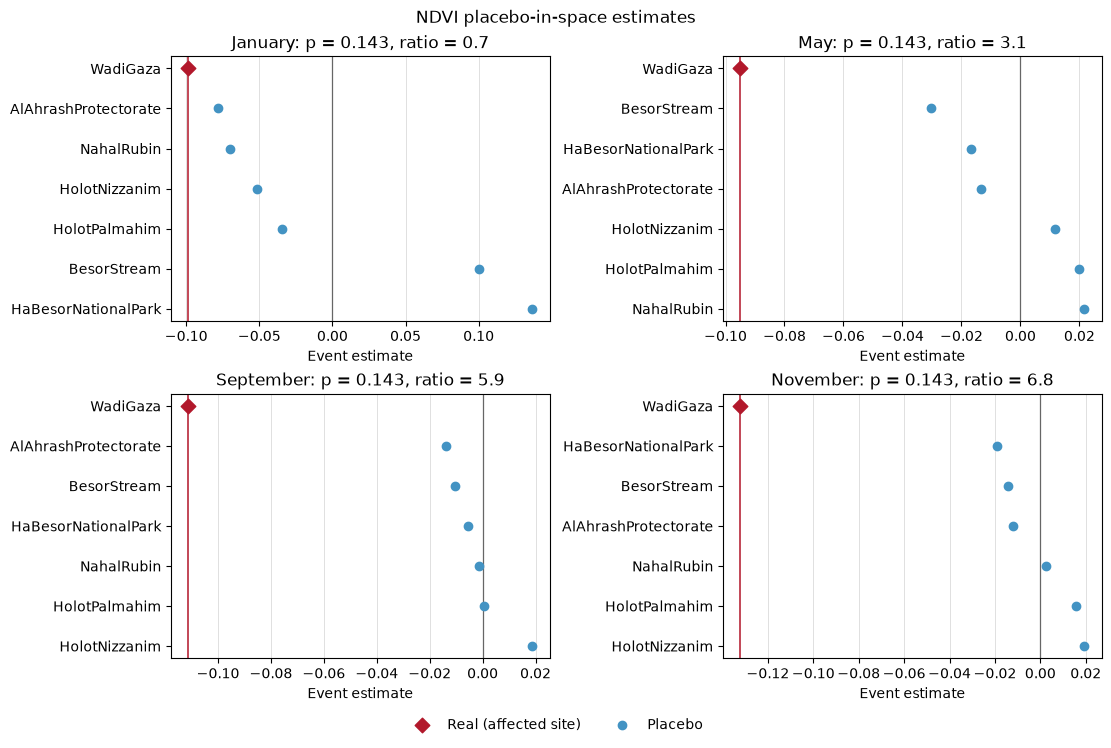

In [3]:
SHOW_INDICES = {PLOT_INDEX}  # indices displayed inline; figures for all are saved

for index in CONFIG.indices:
    index_main, index_space, index_spacetime, index_anomalies = load_outputs(index)
    plot_dir = CONFIG.output_dir / index / "plots"
    fig, axes = plot_placebo_space(index_space)
    fig.suptitle(f"{index} placebo-in-space estimates")
    save_figure(fig, plot_dir / "placebo_space.png")
    plt.show() if index in SHOW_INDICES else plt.close(fig)

## Placebo-in-space-and-time

Each panel ranks the 34 fake-event estimates (the second event pair is dropped
before fitting) against the real estimate, drawn as the highlighted vertical
line. The title carries the month's one-sided p-value (minimum 1/35).

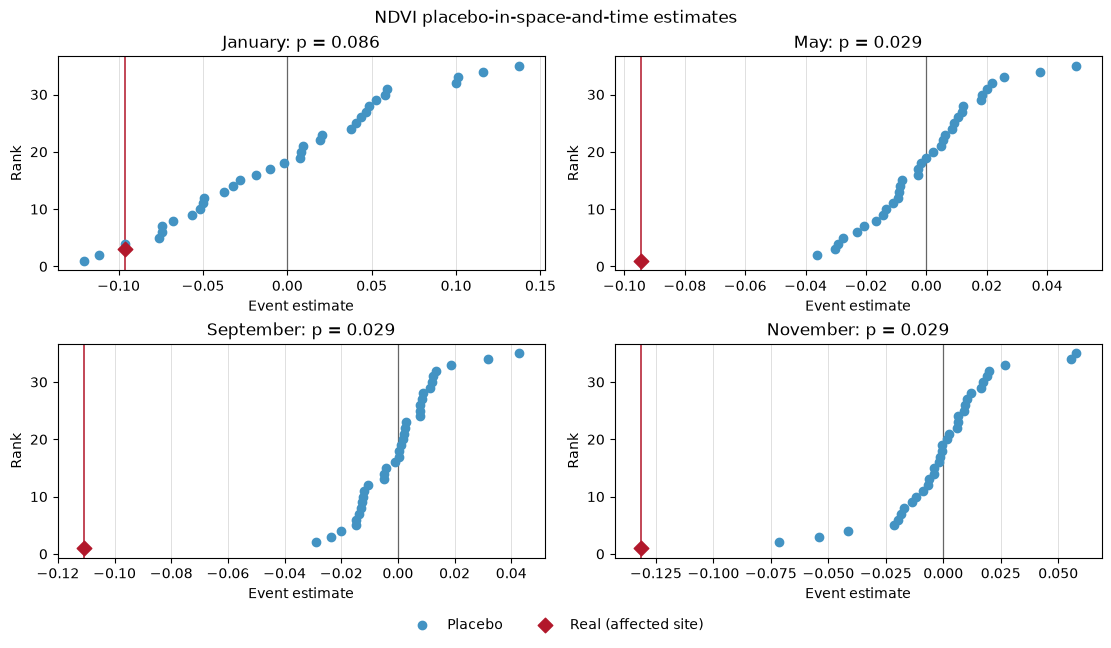

In [4]:
for index in CONFIG.indices:
    index_main, index_space, index_spacetime, index_anomalies = load_outputs(index)
    plot_dir = CONFIG.output_dir / index / "plots"
    fig, axes = plot_placebo_spacetime(index_spacetime)
    fig.suptitle(f"{index} placebo-in-space-and-time estimates")
    save_figure(fig, plot_dir / "placebo_spacetime.png")
    plt.show() if index in SHOW_INDICES else plt.close(fig)

## Sensitivity of the event estimate

Each panel shows the event estimate and its 95% CI for one month across the
primary specification, the τ sensitivities, and both missing-SE policies.

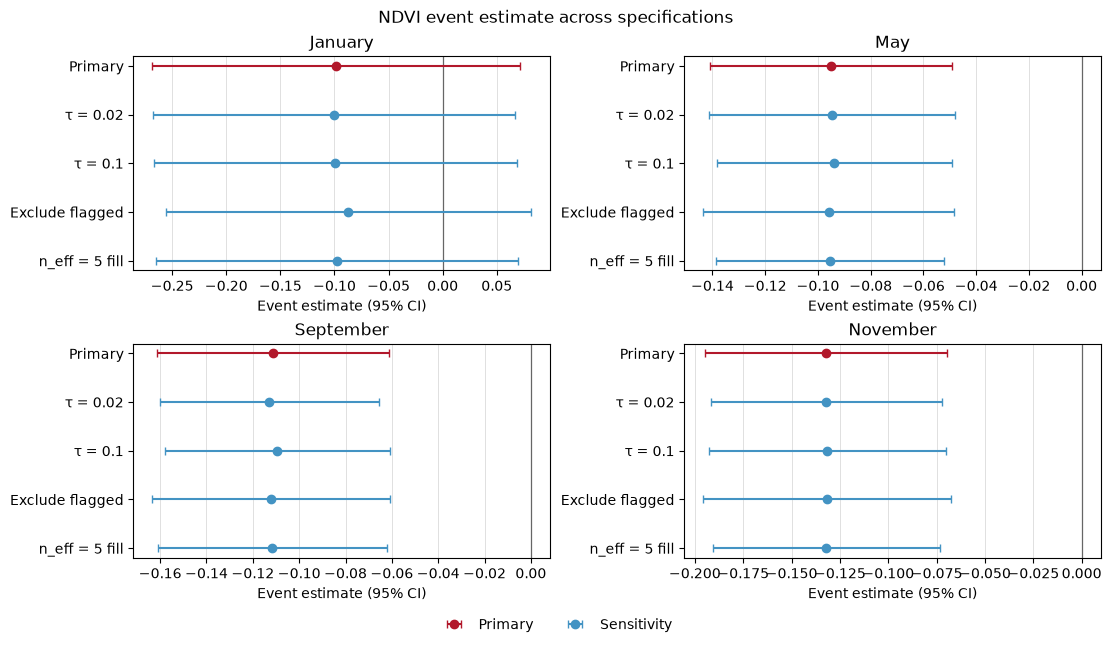

In [5]:
for index in CONFIG.indices:
    index_main, index_space, index_spacetime, index_anomalies = load_outputs(index)
    plot_dir = CONFIG.output_dir / index / "plots"
    fig, axes = plot_sensitivity_forest(index_main)
    fig.suptitle(f"{index} event estimate across specifications")
    save_figure(fig, plot_dir / "sensitivity_forest.png")
    plt.show() if index in SHOW_INDICES else plt.close(fig)

## Change trajectories in context

Each panel shows every site's mean change across consecutive year pairs for one
month: comparison sites in grey, the affected site highlighted, and the event
year pairs shaded. The story the model quantifies is visible directly: the
affected site moves with the pack until the event pairs.

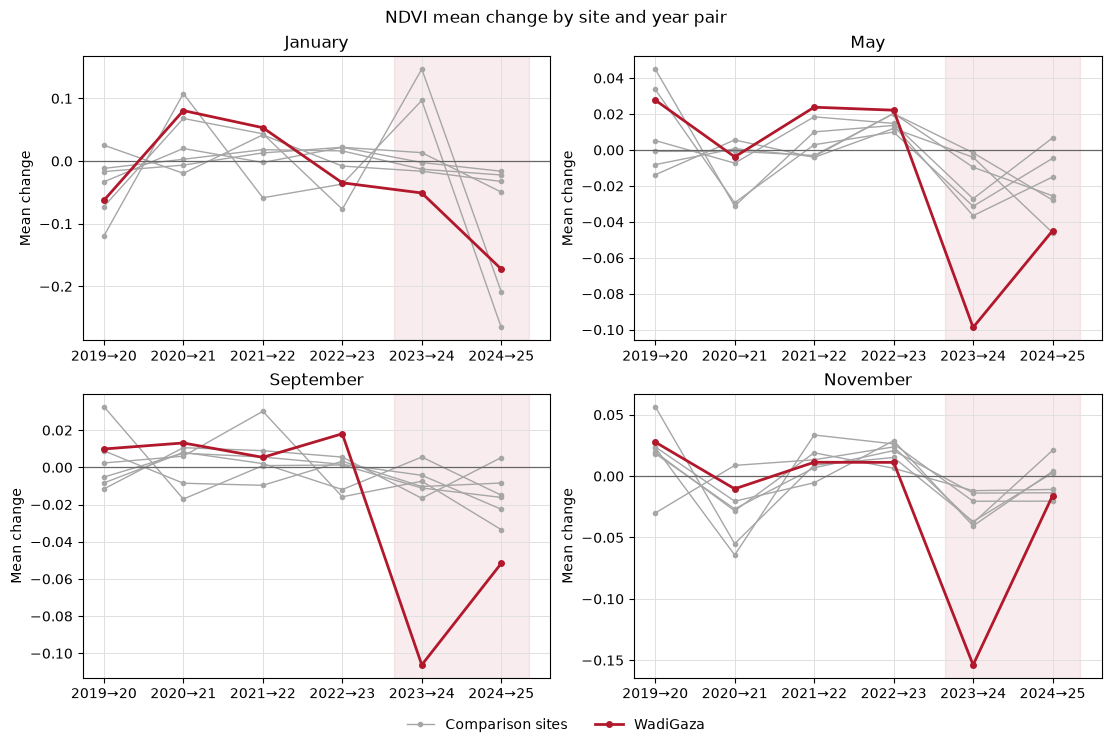

In [6]:
CHANGE_CI_DIR = ROOT / "outputs" / "change_ci"

for index in CONFIG.indices:
    change_results = pd.read_csv(CHANGE_CI_DIR / index / "results.csv")
    plot_dir = CONFIG.output_dir / index / "plots"
    fig, axes = plot_change_trajectories(
        change_results, CONFIG.affected_site, CONFIG.event_pairs, months=CONFIG.months
    )
    fig.suptitle(f"{index} mean change by site and year pair")
    save_figure(fig, plot_dir / "change_trajectories.png")
    plt.show() if index in SHOW_INDICES else plt.close(fig)

## Deviation-from-counterfactual heatmaps

Each cell is one site × year pair's deviation from the fitted fixed-effects
counterfactual: what remains after removing each site's typical drift and each
year's shared shock. Event cells are outlined; their deviations equal the
fitted event coefficients (β and β′) exactly, while every other cell is the
weighted fit's residual. Brown is a decrease and teal an increase.

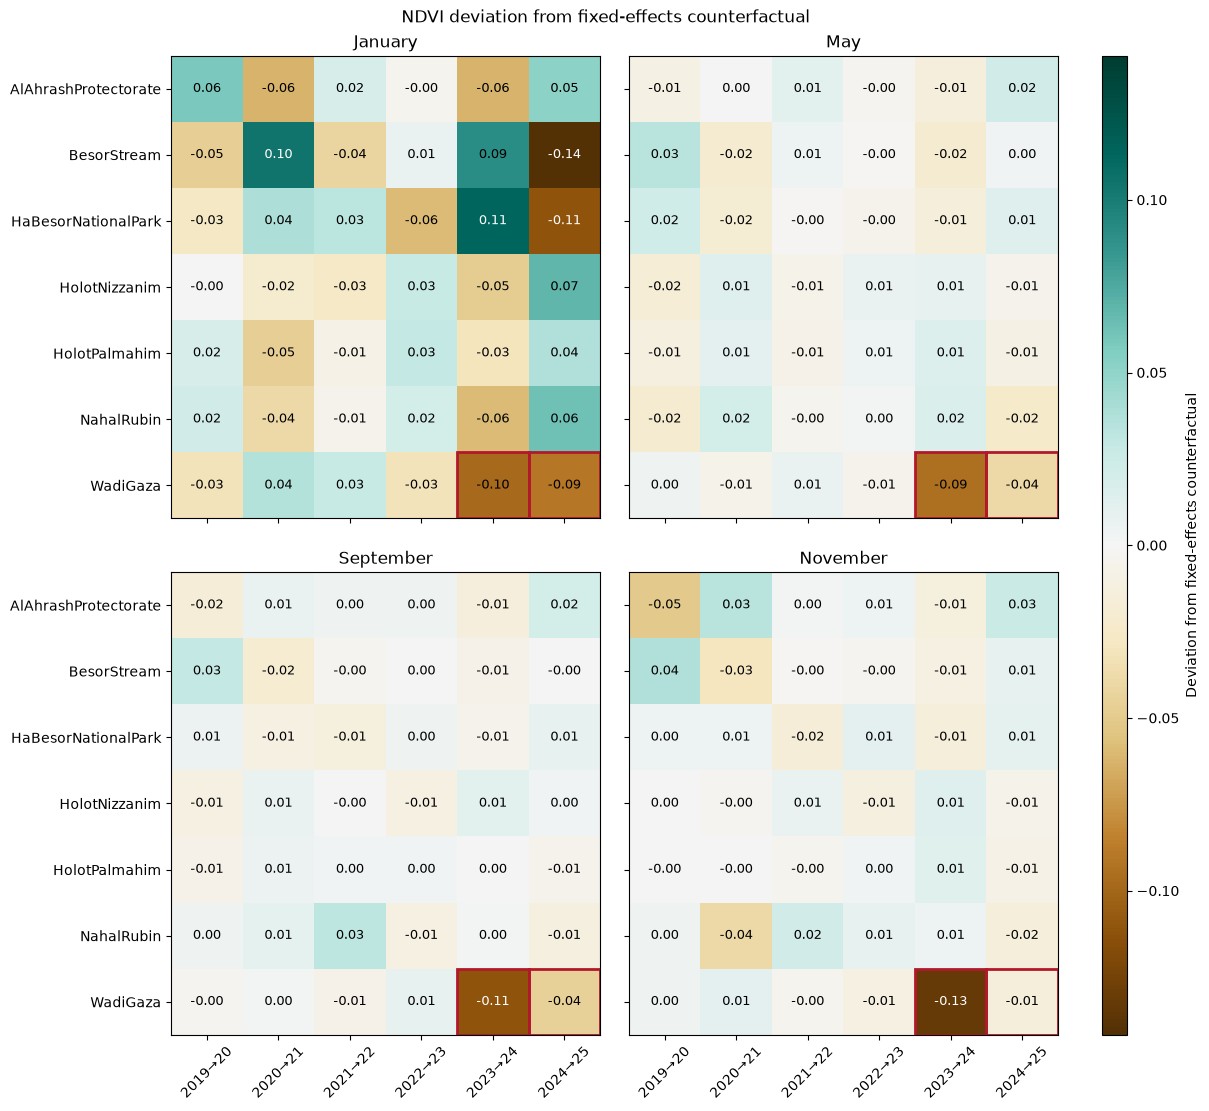

In [7]:
for index in CONFIG.indices:
    _, _, _, index_anomalies = load_outputs(index)
    plot_dir = CONFIG.output_dir / index / "plots"
    fig, axes = plot_anomaly_heatmap(index_anomalies)
    fig.suptitle(f"{index} deviation from fixed-effects counterfactual")
    save_figure(fig, plot_dir / "anomaly_heatmap.png")
    plt.show() if index in SHOW_INDICES else plt.close(fig)

## Observed vs counterfactual for the affected site

The dashed line is the model's counterfactual for the affected site (its own
typical drift plus each year's shared shock); the solid line is what was
observed. The annotated gap at the first event pair equals the event
estimate β.

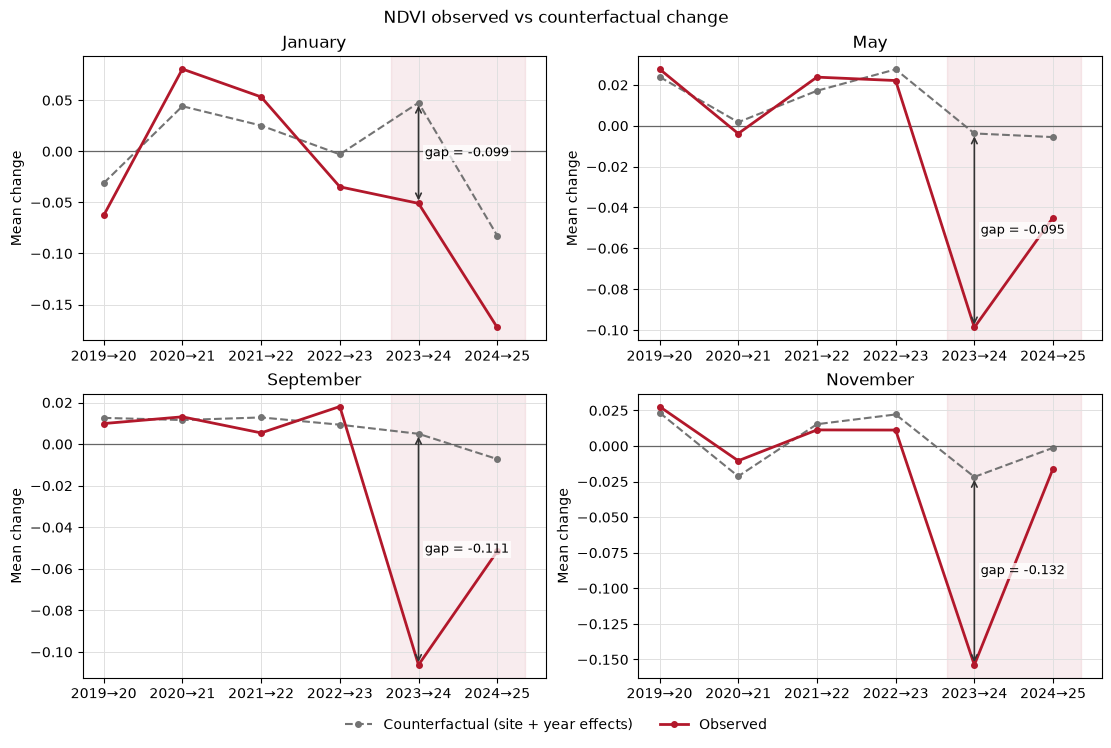

In [8]:
for index in CONFIG.indices:
    _, _, _, index_anomalies = load_outputs(index)
    plot_dir = CONFIG.output_dir / index / "plots"
    fig, axes = plot_observed_vs_counterfactual(
        index_anomalies, CONFIG.affected_site, CONFIG.event_pairs
    )
    fig.suptitle(f"{index} observed vs counterfactual change")
    save_figure(fig, plot_dir / "observed_vs_counterfactual.png")
    plt.show() if index in SHOW_INDICES else plt.close(fig)

## Combined evidence per month

One panel per month stacking the lines of evidence on a shared axis: the event
estimate with its 95% CI, the affected site's own pre-event pairs as time
placebos (hollow markers, a subset of the space-and-time estimates), the six
placebo-in-space estimates, and the 34 placebo-in-space-and-time estimates.
Titles carry both one-sided permutation p-values (floors 1/7 ≈ 0.143 and
1/35 ≈ 0.029).

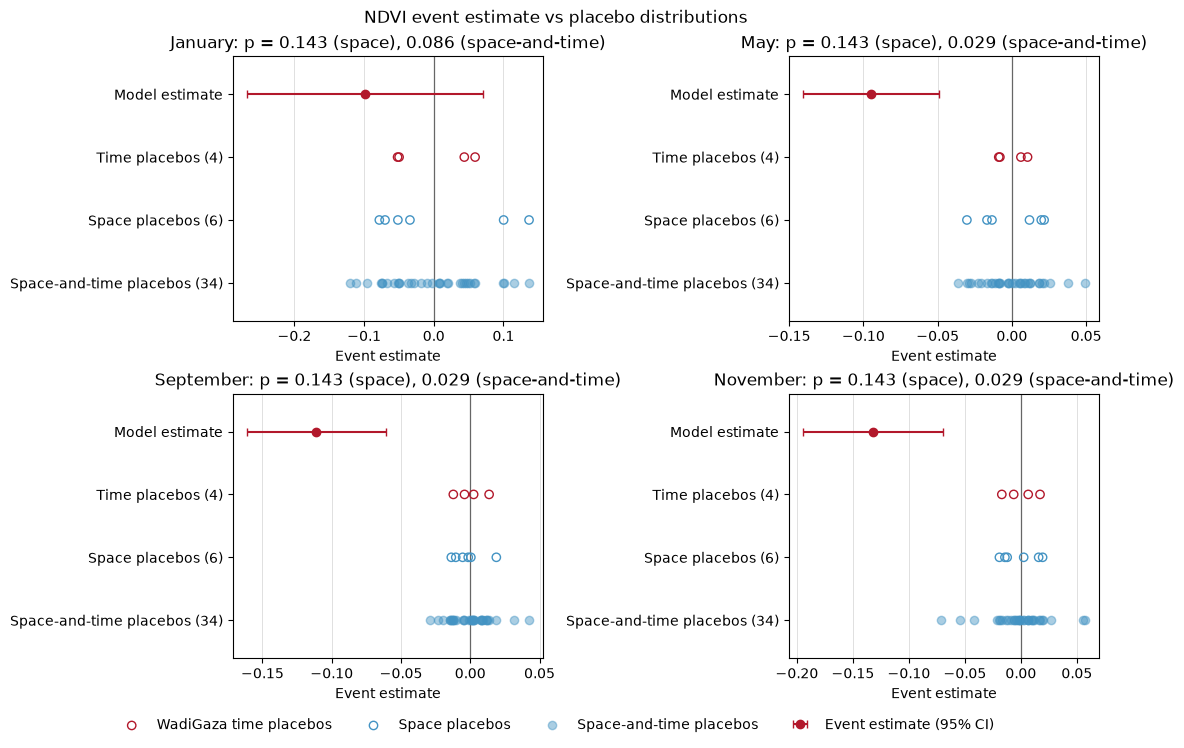

In [9]:
for index in CONFIG.indices:
    index_main, index_space, index_spacetime, _ = load_outputs(index)
    plot_dir = CONFIG.output_dir / index / "plots"
    fig, axes = plot_combined_evidence(index_main, index_space, index_spacetime)
    fig.suptitle(f"{index} event estimate vs placebo distributions")
    save_figure(fig, plot_dir / "combined_evidence.png")
    plt.show() if index in SHOW_INDICES else plt.close(fig)

## Index-level trajectories in context

Annual mean index levels per site from the saved `index_ci` results, with the
affected site highlighted and its spatially adjusted CI band shown. The
observation years following the event onset are shaded. This is descriptive
context in levels; the statistical model works on changes.

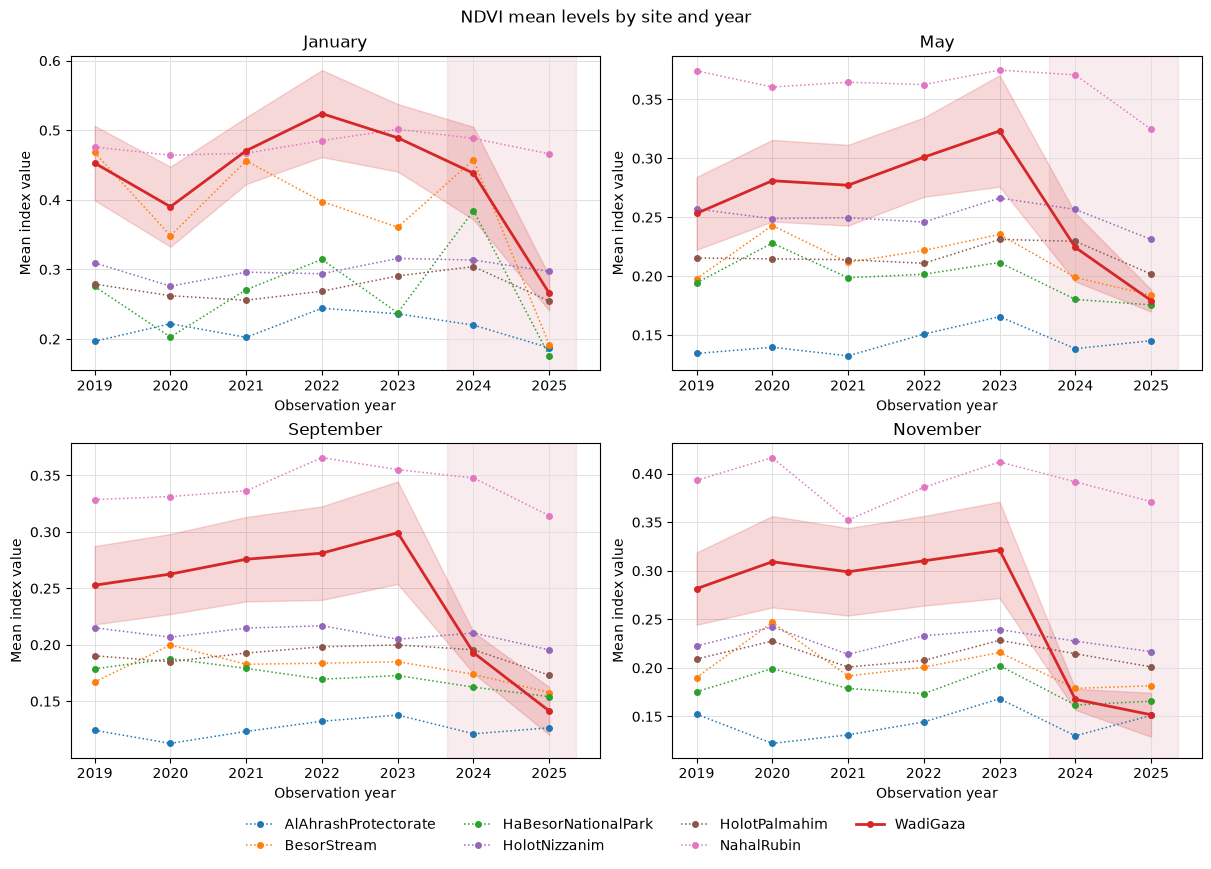

In [10]:
INDEX_CI_DIR = ROOT / "outputs" / "index_ci"
EVENT_YEARS = sorted({pair[1] for pair in CONFIG.event_pairs})

for index in CONFIG.indices:
    level_results = pd.read_csv(INDEX_CI_DIR / index / "results.csv")
    plot_dir = CONFIG.output_dir / index / "plots"
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
    for ax, month in zip(axes.flat, CONFIG.months):
        plot_index_timeseries(
            level_results, group_by="study_area", filters={"month": month},
            show_ci_for=CONFIG.affected_site, highlight=CONFIG.affected_site, ax=ax,
        )
        ax.axvspan(
            min(EVENT_YEARS) - 0.35, max(EVENT_YEARS) + 0.35,
            color="#b2182b", alpha=0.08, zorder=0,
        )
        ax.set_title(month_name(month))
    add_shared_legend(fig, axes)
    fig.suptitle(f"{index} mean levels by site and year")
    save_figure(fig, plot_dir / "level_trajectories.png")
    plt.show() if index in SHOW_INDICES else plt.close(fig)

## Summary table

In [11]:
from IPython.display import Markdown

Markdown((CONFIG.output_dir / PLOT_INDEX / "did_summary.md").read_text(encoding="utf-8"))

# Weighted fixed-effects model on index change

Primary specification: tau = 0.05, largest-SE fill, affected site WadiGaza. NDVI is the primary index; other indices are robustness checks. Supplementary months are flagged in their month label.

## NDVI (primary)

| Month | beta 2023–24 (95% CI) | p | beta' 2024–25 (95% CI) | sigma_u | Placebo-space p | Placebo-space-time p |
| --- | --- | --- | --- | --- | --- | --- |
| January (supplementary) | -0.099 (-0.268, 0.071) | 0.24 | -0.090 (-0.255, 0.075) | 0.0628 | 0.143 | 0.086 |
| May | -0.095 (-0.141, -0.049) | 0.00022 | -0.039 (-0.086, 0.008) | 0.0149 | 0.143 | 0.029 |
| September | -0.111 (-0.161, -0.061) | 9.5e-05 | -0.044 (-0.094, 0.006) | 0.0100 | 0.143 | 0.029 |
| November | -0.132 (-0.195, -0.070) | 0.00017 | -0.015 (-0.077, 0.048) | 0.0177 | 0.143 | 0.029 |
